# 01 · Membaca sentimen dan topik layanan kepolisian

**Durasi 50 menit · peserta umum · CPU**

Setelah praktik ini, Anda dapat membedakan sentimen dengan topik, melatih pengklasifikasi sederhana, membaca kesalahannya, lalu menghubungkan topik dengan sentimen untuk bahan diskusi perbaikan layanan.

| Tahap | Menit | Hasil |
|---|---:|---|
| Persiapan dan membaca data | 5 + 5 | Mengenal sumber dan tiga label |
| Latih, validasi, dan uji sentimen | 12 | Skor, confusion matrix, contoh kesalahan |
| Uji pada konteks polisi | 6 | Memahami pergeseran domain |
| Topic modeling | 12 | Kata kunci dan contoh tiap topik |
| Gabungkan hasil dan diskusi | 10 | Peta ringkas beserta batas interpretasi |

**Hubungan dengan slide:** bagian sentimen slide11–16, topik17–20, dan penggabungan21–23. Slide memperkenalkan BERTopic/Transformer. Praktik inti memakai **TF-IDF + Logistic Regression dan NMF** agar pelatihan terlihat dan berjalan di CPU. NMF mempelajari pola kata, bukan embedding semantik BERTopic. Notebook ini tidak mengklaim melatih IndoBERT atau menjalankan BERTopic.

**Data nyata:** SmSA (ulasan/komentar umum). **Data domain polisi:**72 komentar sintetis dari LLM, enam aspek layanan, belum divalidasi manusia. Keduanya dipisahkan. Hasil sintetis tidak mengukur opini masyarakat nyata.


## 1. Persiapan · 5 menit

Jalankan sel secara berurutan melalui **Runtime → Run all** (Colab) atau **Run → Run All Cells** (Jupyter).
Di komputer: jalankan `pip install -r requirements.txt` sekali sebelum membuka notebook.
Di Colab: buka notebook ini, lalu unggah ZIP folder materi kb_kik saat diminta. Alternatifnya, mount Google Drive dan isi `PROJECT_ROOT` dengan lokasi repo.
Tidak perlu GPU, API key, atau akun layanan AI. Internet hanya diperlukan untuk instalasi awal/unggah ZIP. Versi paket yang dipakai saat pengujian dicantumkan di `requirements.txt`.


In [1]:
import importlib.util, subprocess, sys
# Hanya memasang paket yang belum ada; pada environment yang sudah siap, sel ini offline.
packages = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
            "sklearn":"scikit-learn==1.6.1", "matplotlib":"matplotlib==3.10.3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Paket dasar tersedia. Python", sys.version.split()[0])

Paket dasar tersedia. Python 3.12.14


In [2]:
TOPIC = '01_pelayanan'
from pathlib import Path
import os,sys,json,zipfile,importlib.util

# Isi lokasi folder repo di sini jika deteksi otomatis gagal.
PROJECT_ROOT = os.environ.get("POLRI_TUTORIAL_ROOT", "")
def is_repo(path):
    return (path / "dataset/01_smsa_final_train.csv").is_file() and (path / "notebook").is_dir()
def find_repo():
    if PROJECT_ROOT:
        return Path(PROJECT_ROOT).expanduser().resolve()
    return next((p for p in [Path.cwd(),*Path.cwd().parents] if is_repo(p)), None)

ROOT = find_repo()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if ROOT is None and IN_COLAB:
    from google.colab import files
    print("Unggah satu ZIP folder materi kb_kik agar notebook dan dataset tersedia.")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Unggah tepat satu ZIP folder materi kb_kik.")
    target = Path(os.environ.get("POLRI_COLAB_UPLOAD_DIR", "/content/polri_tutorial"))
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (target / item.filename).resolve().is_relative_to(target.resolve()):
                raise ValueError("Path ZIP tidak aman.")
        archive.extractall(target)
    roots = [p.parent for p in target.rglob("README.md") if is_repo(p.parent)]
    if len(roots) != 1:
        raise ValueError("Struktur ZIP tidak sesuai; isi PROJECT_ROOT secara manual.")
    ROOT = roots[0]
if ROOT is None or not is_repo(ROOT):
    raise FileNotFoundError("Ekstrak repo lengkap atau isi PROJECT_ROOT dengan lokasi repo.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
from pathlib import Path
import json,re,unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay,
                             f1_score,precision_score,recall_score)
SEED=42
LABELS=['negative','neutral','positive']
IE_FIELDS=['pelapor','korban','terlapor','saksi','waktu_kejadian','lokasi_kejadian','nominal_disebut','bukti_tersedia']
np.random.seed(SEED)
pd.set_option("display.max_colwidth",115)
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
DATASET = ROOT / "dataset"
OUT = ROOT / "outputs" / TOPIC
OUT.mkdir(parents=True,exist_ok=True)
print("Repo:",ROOT.name,"| Hasil:",OUT.relative_to(ROOT))

Repo: kb_kik | Hasil: outputs\01_pelayanan


## 2. Data, label, dan pembagian · 5 menit

`positive`: apresiasi/penilaian baik, `negative`: keluhan/penilaian buruk, `neutral`: informasi atau pertanyaan tanpa penilaian jelas. Sarkasme dan teks campuran dapat menyulitkan model.

**Train** untuk belajar, **validation** untuk memilih pengaturan, **test** untuk pemeriksaan akhir. Jumlah sudah berubah dari sumber karena deduplikasi. Pemeriksaan otomatis mencegah teks identik antarsplit; parafrasa masih dapat lolos.


In [3]:
# Fungsi yang dipakai pada langkah berikut.
def norm(text):
    return ' '.join(unicodedata.normalize('NFKC',str(text)).casefold().split())

def load_splits(root,prefix):
    splits={s:pd.read_csv(Path(root)/'dataset'/f'{prefix}_final_{s}.csv') for s in ['train','val','test']}
    seen=[]
    for s,df in splits.items():
        assert not df['id'].duplicated().any(),f'Duplicate id: {s}'
        column='content_cleaned' if 'content_cleaned' in df else 'content'
        assert df[column].notna().all() and df[column].str.strip().ne('').all()
        current=set(df[column].map(norm));assert len(current)==len(df),f'Duplicate input: {s}'
        for previous in seen:assert not previous & current,'Cross-split text overlap'
        seen.append(current)
    ids=[set(df.id) for df in splits.values()]
    assert all(not ids[i]&ids[j] for i in range(3) for j in range(i+1,3))
    return splits['train'],splits['val'],splits['test']

def summarize_splits(train,val,test):
    return pd.DataFrame([{'split':s,'rows':len(df),**df.label.value_counts().to_dict()}
                         for s,df in [('train',train),('val',val),('test',test)]]).fillna(0)

,split,rows,positive,negative,neutral
0,train,8114,4684,2563,867
1,val,2029,1171,641,217
2,test,2536,1464,801,271


,content,label
4133,penasaran karena kata nya lagi hits banget . saya datang ke cabang yang di jalan dipatiukur bandung kira-kira j...,negative
7488,kpu putuskan dapat perbaikan diperpanjang,neutral
1319,thread lu faedah sekali senang gua baca nya . dari prolog nya saja sudah bagus sekali jet . bangga sama lu,positive


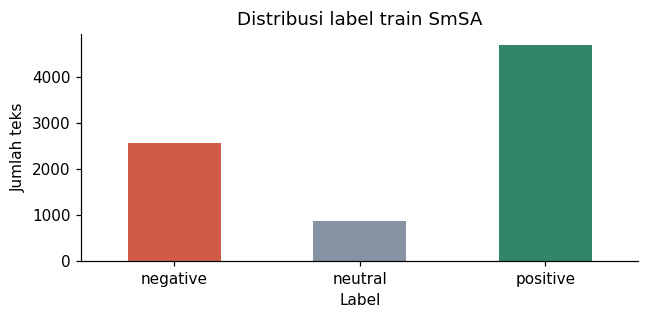

In [4]:
train, val, test = load_splits(ROOT, "01_smsa")
display(summarize_splits(train, val, test))
display(train.groupby("label", group_keys=False).sample(1, random_state=SEED)[["content", "label"]])
fig, ax = plt.subplots(figsize=(6, 3))
train.label.value_counts().reindex(LABELS).plot.bar(ax=ax, color=["#d15a48", "#8593a3", "#32856b"])
ax.set(title="Distribusi label train SmSA", ylabel="Jumlah teks", xlabel="Label")
plt.xticks(rotation=0); plt.tight_layout(); plt.show(); plt.close(fig)

## 3. Model belajar dari contoh · 12 menit

TF-IDF memberi bobot pada kata/frasa. Logistic Regression belajar membedakan label dari bobot tersebut. `Pipeline` memastikan kosakata hanya dipelajari dari train. Kata **tidak**, **belum**, tanda baca, dan slang dipertahankan; menghapusnya sembarangan dapat membalik makna.

Kita mencoba dua kekuatan regularisasi (`C`). Nilai terbaik dipilih dengan **macro-F1 validation** agar kelas netral yang lebih sedikit ikut diperhatikan. Akurasi tinggi saja dapat menyembunyikan kegagalan kelas kecil.


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score

models, validation_rows = {}, []
for C in [0.5, 2.0]:
    model = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=40000)),
        ("classifier", LogisticRegression(C=C, max_iter=500, random_state=SEED))])
    model.fit(train.content_cleaned, train.label)
    pred = model.predict(val.content_cleaned)
    models[C] = model
    validation_rows.append({"C": C, "macro_f1": f1_score(val.label, pred, average="macro")})
validation_scores = pd.DataFrame(validation_rows).sort_values("macro_f1", ascending=False)
display(validation_scores)
best_C = float(validation_scores.iloc[0].C)
sentiment_model = models[best_C]
print("C dipilih dari validation:", best_C)

,C,macro_f1
1,2.0,0.839523
0,0.5,0.777774


C dipilih dari validation: 2.0


In [6]:
# Fungsi yang dipakai pada langkah berikut.
def evaluate_classification(y_true,y_pred,labels,title,output_dir):
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    report=pd.DataFrame(classification_report(y_true,y_pred,labels=labels,output_dict=True,zero_division=0)).T
    fig,ax=plt.subplots(figsize=(6.4,4.8))
    ConfusionMatrixDisplay(confusion_matrix(y_true,y_pred,labels=labels),display_labels=labels).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(title);fig.tight_layout();fig.savefig(output_dir/'confusion_matrix.png',dpi=150);plt.show();plt.close(fig)
    report.to_csv(output_dir/'classification_report.csv')
    return report

def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')

,model,accuracy,macro_f1
0,Selalu kelas mayoritas,0.577287,0.244000
1,TF-IDF + Logistic Regression,0.873028,0.829753


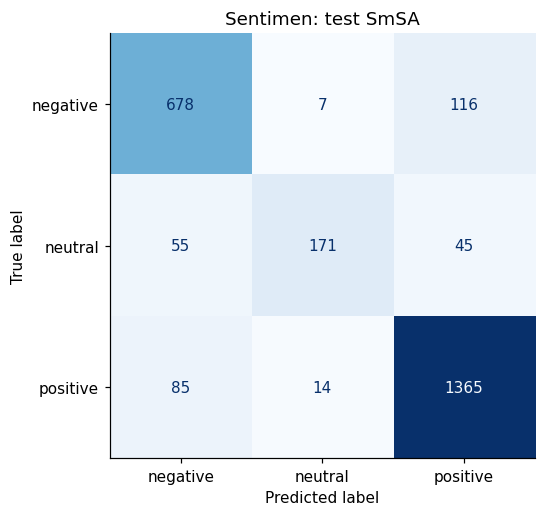

,precision,recall,f1-score,support
negative,0.829,0.846,0.838,801.000
neutral,0.891,0.631,0.739,271.000
positive,0.894,0.932,0.913,1464.000
accuracy,0.873,0.873,0.873,0.873
macro avg,0.871,0.803,0.830,2536.000
weighted avg,0.873,0.873,0.871,2536.000


,id,content,label,prediksi
1,SMSA-valid-00169,"makan malam yang sestrategis di sini dengan menu pilihan khas sunda , namun mungkin perlu dipikirkan juga bagai...",negative,positive
15,SMSA-train-00907,"sudah sebulan lebih tidak makan indomie , sekali nya makan langsung bikin dua porsi indomie goreng jumbo .",neutral,positive
22,SMSA-train-03188,"sukses selalu untuk demokrat , tahun 2018 adalah tahun kerja untuk menuai hasil yang diharapkan . maju terus pa...",positive,neutral
25,SMSA-test-00296,"di usia 57 tahun , saat nya gerakan pramuka di tanah air menjawab tantangan zaman baru . anggota pramuka harus ...",neutral,negative
26,SMSA-train-10843,"nyinyiri pembangunan infrastruktur pemerintahan jokowi , fadli zon : kata nya revolusi mental",neutral,negative


In [7]:
# Test pertama kali dibaca oleh evaluasi model setelah pilihan C sudah tetap.
test_prediction = sentiment_model.predict(test.content_cleaned)
baseline = DummyClassifier(strategy="most_frequent").fit(train.content_cleaned, train.label)
baseline_prediction = baseline.predict(test.content_cleaned)
comparison = pd.DataFrame([
    {"model": name, "accuracy": accuracy_score(test.label, pred),
     "macro_f1": f1_score(test.label, pred, average="macro")}
    for name, pred in [("Selalu kelas mayoritas", baseline_prediction), ("TF-IDF + Logistic Regression", test_prediction)]])
display(comparison)
report = evaluate_classification(test.label, test_prediction, LABELS, "Sentimen: test SmSA", OUT)
display(report.round(3))
errors = test.loc[test.label.ne(test_prediction), ["id", "content", "label"]].copy()
errors["prediksi"] = test_prediction[test.label.ne(test_prediction)]
display(errors.head(5))
save_json(OUT / "metrics.json", {"best_C": best_C, "test_macro_f1": float(f1_score(test.label, test_prediction, average="macro")),
                               "majority_macro_f1": float(f1_score(test.label, baseline_prediction, average="macro"))})

**Baca hasilnya:** baris confusion matrix adalah label acuan, kolom adalah prediksi. Lihat sel di luar diagonal dan contoh teksnya. Pilih satu kesalahan: adakah konteks, sarkasme, atau campuran pujian-keluhan? Jangan mengganti pengaturan berdasarkan test lalu melaporkan skor test yang sama sebagai evaluasi baru.

## 4. Apakah model ulasan memahami layanan polisi? · 6 menit

Model yang baik pada restoran belum tentu baik pada layanan polisi. Ini **pergeseran domain**. Kita uji model yang sama, tanpa melatih ulang, pada72 komentar sintetis yang tidak dimasukkan ke pelatihan SmSA. Label acuan sintetis juga belum diaudit manusia.


In [8]:
# Fungsi yang dipakai pada langkah berikut.
def clean_text(text):
    """Same transformation used to prepare the classification datasets."""
    text=unicodedata.normalize('NFKC',str(text))
    text=re.sub(r'https?://\S+|www\.\S+','[URL]',text)
    text=re.sub(r'@[\w]+','[AKUN]',text)
    return ' '.join(text.split())

In [9]:
police = pd.read_csv(DATASET / "01_pelayanan_sintetis_cleaned.csv")
police["predicted_sentiment"] = sentiment_model.predict(police.content_cleaned)
display(pd.crosstab(police.label, police.predicted_sentiment).reindex(index=LABELS, columns=LABELS, fill_value=0))
display(police.loc[police.label.ne(police.predicted_sentiment), ["content", "label", "predicted_sentiment"]].head(5))
print("Macro-F1 demonstrasi sintetis:", round(f1_score(police.label, police.predicted_sentiment, average="macro"), 3))
YOUR_TEXT = "Petugas menjelaskan syarat SIM dengan sabar, terima kasih."
display(pd.DataFrame({"teks": [YOUR_TEXT], "prediksi": sentiment_model.predict([clean_text(YOUR_TEXT)])}))

predicted_sentiment,negative,neutral,positive
label,,,
negative,21,1,2
neutral,6,15,3
positive,9,2,13


,content,label,predicted_sentiment
2,"Saya gagal ujian praktik, tetapi arahan petugas tetap sopan dan jadwal ujian ulang dijelaskan. Pelayanannya baik.",positive,negative
6,"Mantap sekali layanan SIM ini, tiga kali datang sistemnya selalu rusak. Benar-benar buang waktu.",negative,positive
8,Apakah perpanjangan SIM bisa dilakukan hari Sabtu? Saya belum menemukan jadwal loketnya.,neutral,negative
9,Informasi yang saya baca menyebut pemohon SIM perlu membawa identitas dan dokumen kesehatan.,neutral,positive
11,Saya sedang mencari alamat tempat ujian praktik SIM yang baru.,neutral,positive


Macro-F1 demonstrasi sintetis: 0.678


,teks,prediksi
0,"Petugas menjelaskan syarat SIM dengan sabar, terima kasih.",positive


**Coba sendiri:** ubah `YOUR_TEXT` menjadi kalimat tanpa kata emosional, lalu kalimat sarkasme. Apakah prediksi sesuai penilaian Anda? Skor model tidak otomatis menunjukkan kebenaran label ataupun kualitas layanan.

## 5. Menemukan topik tanpa label · 12 menit

Kini pertanyaannya berubah: **apa yang dibicarakan?** NMF memecah matriks bobot kata menjadi pola topik. Kita **tidak** memasukkan label sentimen atau `topic_reference` sebagai fitur. Satu teks memiliki beberapa bobot topik; `argmax` hanya menyederhanakan tampilan.

`N_TOPICS=6` adalah pengaturan awal untuk demonstrasi, bukan hasil penemuan bahwa layanan polisi pasti memiliki enam topik. Manusia membaca kata kunci dan contoh, lalu memberi nama. Model ini eksplorasi seluruh korpus kecil, bukan prediksi pada holdout.


In [10]:
from sklearn.decomposition import NMF
topic_input = pd.read_csv(DATASET / "01_topic_modeling_input.csv")
assert not {"label", "topic_reference"} & set(topic_input.columns)
STOPWORDS = "yang dan di ke dari ini itu saya kami kita dengan untuk pada ada adalah atau tapi tetapi sudah belum masih saat juga bisa akan sangat tidak nya petugas polisi".split()
N_TOPICS = 6  # Latihan: coba 4 atau 8 dan baca kembali contohnya.
topic_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.85, stop_words=STOPWORDS)
X_topics = topic_vectorizer.fit_transform(topic_input.content_cleaned)
topic_model = NMF(n_components=N_TOPICS, init="nndsvda", random_state=SEED, max_iter=600)
weights = topic_model.fit_transform(X_topics)
terms = topic_vectorizer.get_feature_names_out()
topic_keywords = pd.DataFrame([
    {"topic_id": i, "kata_kunci": ", ".join(terms[component.argsort()[-7:][::-1]])}
    for i, component in enumerate(topic_model.components_)])
display(topic_keywords)
topic_input["topic_id"] = weights.argmax(axis=1)
topic_input["top_weight"] = weights.max(axis=1)
examples = topic_input.sort_values("top_weight", ascending=False).groupby("topic_id").head(2)
display(examples[["topic_id", "content"]].sort_values("topic_id"))

,topic_id,kata_kunci
0,0,"terima kasih, kasih, terima, membantu, sampai, menjelaskan, sekolah"
1,1,"skck, loket, sim, berkas, jelas, loket skck, selesai"
2,2,"layanan, bantuan, telepon, daring, layanan daring, darurat, kali"
3,3,"tanpa, melapor, diminta, penjelasan, jadi, datang, membuat"
4,4,"jalan, arus, pengalihan, pengalihan arus, mengatur, mencari, dijelaskan"
5,5,"nomor, aplikasi, laporan, pengaduan, nomor registrasi, registrasi, mengirim"


,topic_id,content
48,0,Petugas membantu menyeberangkan anak sekolah saat jalan padat. Terima kasih sudah menjaga mereka.
13,0,Terima kasih petugas SKCK yang mau menjelaskan prosedur kepada ibu saya sampai paham.
22,1,Loket SKCK mengumumkan perubahan jam istirahat selama bulan ini.
12,1,"SKCK saya selesai hari ini, persyaratannya jelas dan petugas membantu cek berkas. Puas."
40,2,"Nomor bantuan berkali-kali saya telepon tidak diangkat, padahal ada kecelakaan. Sangat mengecewakan."
68,2,Apakah nomor telepon akun layanan daring bisa diganti?
31,3,Saya diminta mengulang cerita ke banyak petugas tanpa penjelasan. Melapor jadi melelahkan.
26,3,"Saya awalnya takut melapor, tetapi petugas mendengarkan tanpa menyalahkan. Rasanya sangat terbantu."
49,4,Pengalihan arus pagi ini dijelaskan dengan baik sehingga saya tidak bingung mencari jalan.
54,4,"Jalan macet panjang, tetapi petugas di simpang tidak mengatur arus. Sangat disayangkan."


**Latihan penamaan:** isi kamus `TOPIC_NAMES` dari hasil yang baru Anda baca. Jangan memakai topik acuan generator untuk melatih atau memilih kata model. Topik yang tumpang tindih atau sulit dinamai perlu dicatat, bukan dipaksa menjadi enam kategori rapi.


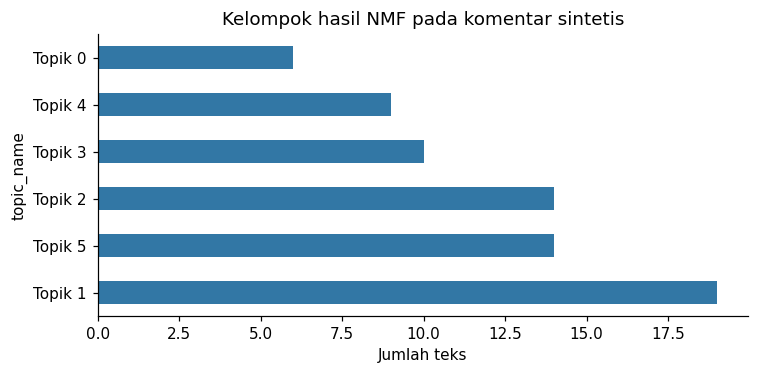

In [11]:
TOPIC_NAMES = {i: f"Topik {i}" for i in range(N_TOPICS)}
# Contoh setelah melihat hasil: TOPIC_NAMES[0] = "Pengurusan SIM" (hanya jika kata dan contohnya mendukung).
topic_input["topic_name"] = topic_input.topic_id.map(TOPIC_NAMES)
fig, ax = plt.subplots(figsize=(7, 3.5))
topic_input.topic_name.value_counts().plot.barh(ax=ax, color="#3277a5")
ax.set(title="Kelompok hasil NMF pada komentar sintetis", xlabel="Jumlah teks")
fig.tight_layout(); fig.savefig(OUT / "topic_counts.png", dpi=150); plt.show(); plt.close(fig)

## 6. Menghubungkan sentimen dan topik · 10 menit

Gabungkan berdasarkan `id`, bukan urutan baris. Kita tampilkan **persentase negatif hasil prediksi** dan **persentase negatif label sintetis** secara terpisah. Selisih keduanya menunjukkan pengaruh kesalahan model pada kesimpulan.

Korpus ini sengaja seimbang per aspek dan sentimen. Peta berikut adalah **latihan membaca keluaran**, bukan dasar menentukan prioritas layanan atau bukti layanan tertentu lebih buruk.


,topic_id,topic_name,volume,pred_negative_pct,reference_negative_pct
0,0,Topik 0,6,0.0,0.0
1,1,Topik 1,19,47.4,36.8
2,2,Topik 2,14,35.7,28.6
3,3,Topik 3,10,100.0,80.0
4,4,Topik 4,9,55.6,11.1
5,5,Topik 5,14,50.0,28.6


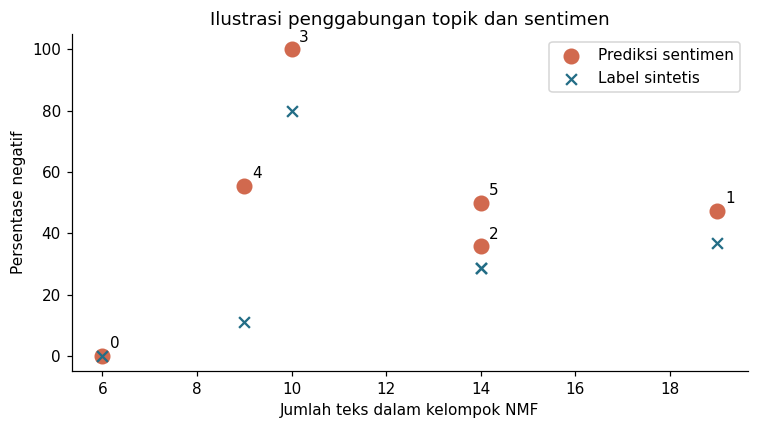

Hasil disimpan di outputs\01_pelayanan


In [12]:
combined = topic_input.merge(police[["id", "label", "predicted_sentiment"]], on="id", validate="one_to_one")
combined["pred_negative"] = combined.predicted_sentiment.eq("negative")
combined["reference_negative"] = combined.label.eq("negative")
summary = combined.groupby(["topic_id", "topic_name"], as_index=False).agg(
    volume=("id", "size"), pred_negative_pct=("pred_negative", "mean"), reference_negative_pct=("reference_negative", "mean"))
summary[["pred_negative_pct", "reference_negative_pct"]] *= 100
display(summary.round(1))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(summary.volume, summary.pred_negative_pct, s=90, color="#d1694e", label="Prediksi sentimen")
ax.scatter(summary.volume, summary.reference_negative_pct, s=50, marker="x", color="#236d86", label="Label sintetis")
for _, r in summary.iterrows(): ax.annotate(str(r.topic_id), (r.volume, r.pred_negative_pct), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Jumlah teks dalam kelompok NMF", ylabel="Persentase negatif", ylim=(-5, 105), title="Ilustrasi penggabungan topik dan sentimen")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "topic_sentiment.png", dpi=150); plt.show(); plt.close(fig)
combined.to_csv(OUT / "sentiment_and_topics.csv", index=False)
summary.to_csv(OUT / "topic_summary.csv", index=False)
print("Hasil disimpan di", OUT.relative_to(ROOT))

### Diskusi penutup

1. Apakah topik ramai berarti layanannya buruk? Faktor apa yang belum ada, seperti jumlah pengguna layanan atau periode waktu?
2. Apa yang terjadi pada peta jika model sering salah pada sarkasme?
3. Data nyata dan validasi manusia apa yang diperlukan sebelum hasil dipakai untuk perbaikan layanan?

**Pengembangan berikutnya:** bandingkan NMF dengan BERTopic (embedding, UMAP, HDBSCAN, c-TF-IDF), dan baseline sentimen dengan IndoBERT terlatih untuk sentimen. BERT dasar tanpa fine-tuning bukan pengklasifikasi sentimen siap pakai. Evaluasi dengan split dan definisi label yang sama sebelum membandingkan skor. Pengembangan tersebut tidak dijalankan oleh notebook ini.

Sumber: [repo pola tutorial](https://github.com/okkyibrohim/tp-css-tutorial), [IndoNLU](https://github.com/IndoNLP/indonlu), [NMF scikit-learn](https://scikit-learn.org/stable/modules/decomposition.html#nmf). Provenans/lisensi data: `dataset/README.md`.
